Device set to use cuda:0


[BERT] accuracy = 0.902
Descargando / cargando modelo Word2Vec GoogleNews-300
[Word2Vec] accuracy = 0.634


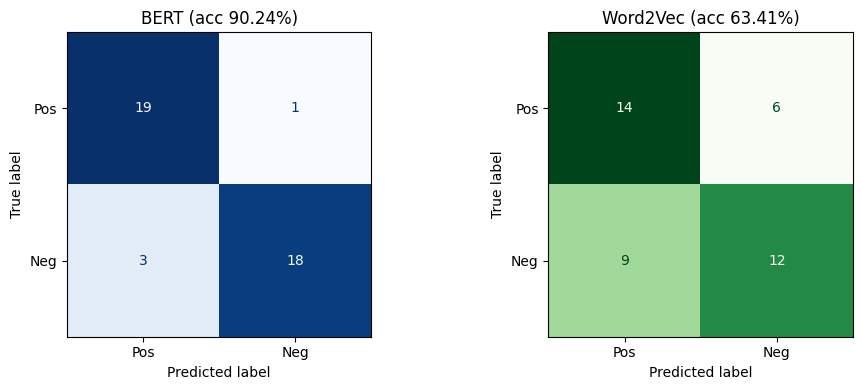

In [ ]:
# Ej 4

import os, warnings, re, string
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics.pairwise import cosine_similarity
from transformers import pipeline
import torch
import gensim.downloader as api


# Datos
DATA_DIR = os.path.join("..", "..", "data", "reseñas")
df_train = pd.read_csv(os.path.join(DATA_DIR, "reseñas_train.csv"))
df_test  = pd.read_csv(os.path.join(DATA_DIR, "reseñas_test.csv"))


# MODELO A – BERT
bert = pipeline(
    "sentiment-analysis",
    model="nlptown/bert-base-multilingual-uncased-sentiment",
    device=0 if torch.cuda.is_available() else -1,
    framework="pt"
)

def sentimiento_bert(texto: str) -> str:
    stars = int(bert(texto, truncation=True)[0]["label"].split()[0])
    return "positiva" if stars >= 4 else "negativa"

df_test["pred_bert"] = df_test["comentario"].apply(sentimiento_bert)
acc_bert = accuracy_score(df_test["etiqueta"], df_test["pred_bert"])
print(f"[BERT] accuracy = {acc_bert:.3f}")


# MODELO B – Word2Vec GoogleNews-300
print("Descargando / cargando modelo Word2Vec GoogleNews-300")
modelo_w2v = api.load("word2vec-google-news-300")

def texto_a_vector(texto: str) -> np.ndarray:
    """Promedio de los embeddings de las palabras que existan en el vocabulario."""
    # tokens: split simple + quitar puntuación
    tokens = [w.strip(string.punctuation).lower()
              for w in texto.split()
              if w.strip(string.punctuation)]
    vectores = [modelo_w2v[w] for w in tokens if w in modelo_w2v]
    return np.mean(vectores, axis=0) if vectores else np.zeros(modelo_w2v.vector_size)

# Vectoriza train y test
df_train["vector"] = df_train["comentario"].apply(texto_a_vector)
df_test ["vector"] = df_test ["comentario"].apply(texto_a_vector)

# Centroides de cada clase
centroide_pos = np.mean(np.stack(df_train.loc[df_train["etiqueta"]=="positiva","vector"]), axis=0)
centroide_neg = np.mean(np.stack(df_train.loc[df_train["etiqueta"]=="negativa","vector"]), axis=0)

def sentimiento_w2v(texto: str) -> str:
    v = texto_a_vector(texto).reshape(1, -1)
    sim_pos = cosine_similarity(v, centroide_pos.reshape(1, -1))[0,0]
    sim_neg = cosine_similarity(v, centroide_neg.reshape(1, -1))[0,0]
    return "positiva" if sim_pos >= sim_neg else "negativa"

df_test["pred_w2v"] = df_test["comentario"].apply(sentimiento_w2v)
acc_w2v = accuracy_score(df_test["etiqueta"], df_test["pred_w2v"])
print(f"[Word2Vec] accuracy = {acc_w2v:.3f}")


# Matrices de confusión

fig, axes = plt.subplots(1, 2, figsize=(10,4))
for ax, col, title, cmap, acc in [
    (axes[0], "pred_bert", "BERT",  "Blues" , acc_bert),
    (axes[1], "pred_w2v" , "Word2Vec", "Greens", acc_w2v),
]:
    cm = confusion_matrix(df_test["etiqueta"], df_test[col], labels=["positiva","negativa"])
    ConfusionMatrixDisplay(cm, display_labels=["Pos","Neg"]).plot(ax=ax, colorbar=False, cmap=cmap)
    ax.set_title(f"{title} (acc {acc:.2%})")
plt.tight_layout()
plt.show()

El clasificador basado en BERT alcanzó una precisión del 90 %, con sólo cuatro errores en el conjunto de prueba, mientras que el enfoque Word2Vec-centroides logró un 63 %, con especial dificultad para identificar reseñas negativas. Esta brecha se debe a que BERT incorpora información contextual y relaciones semánticas completas dentro de la oración, mientras que Word2Vec utiliza un promedio de vectores independientes de contexto, lo que diluye matices y negaciones. Por lo tanto, aunque la estrategia con Word2Vec sirve como línea base liviana, los resultados confirman que los modelos contextuales como BERT proporcionan una clasificación de sentimiento significativamente más fiable para este tipo de datos.